In [3]:
#importing all the necessary libraries
import numpy as np
import matplotlib.pyplot as plt
from scipy.differentiate import derivative

In [4]:
#data and starting values 
X = np.array([[1, 3],[4, 10]])

#target
y= np.array([[5],[6]])

#wieghts
m = np.array([[-1],[2]])  

#bias
b = np.array([[1],[1]])  

n = X.shape[0]
ones = np.ones((n, 1))

learning_rate = 0.01               
num_updates = 3



In [5]:
def derivative_function(equation,x0):
    f = np.vectorize(equation)
    return float(derivative(f, x0).df)

print(
      round(derivative_function(lambda x: x**2 + 3*x, 2.0), 6))

7.0


In [6]:
def cost(m,b):
     """MSE as a matrix expression: J = (1/n) * e^T e, with e = Xm + b - y."""
     e = X @ m + b - y
     return ((1/n) * (e.T @ e)).item()

In [7]:
def scipy_gradient(m_, b_):
    """Gradient of J obtained with SciPy, used to check th formulas."""
    dm1 = derivative_function(lambda v: cost(np.array([[v], [m_[1, 0]]]), b_), m_[0, 0])
    dm2 = derivative_function(lambda v: cost(np.array([[m_[0, 0]], [v]]), b_), m_[1, 0])
    # b is the vector [b, b], so vary the shared bias value
    db = derivative_function(lambda v: cost(m_, v * ones), b_[0, 0])
    return dm1, dm2, db

In [8]:
# Gradient descent, every step visible

history_m1, history_m2, history_b, history_J = [], [], [], []

for step in range(num_updates+1):
    y_hat = X @ m + b

    error = y_hat-y

    J= ((error.T @ error)/n).item()

    history_m1.append(m[0, 0])
    history_m2.append(m[1, 0])
    history_b.append(b[0, 0])
    history_J.append(J)

    print(f"\n--- Iteration {step} ---")
    print("m      =", m.ravel())
    print("b      =", b.ravel())
    print("y_hat  =", y_hat.ravel())
    print("error  =", error.ravel())
    print("MSE J  =", J)

    if step == num_updates:
        break

    # Step C: gradients (matrix form)
    grad_m = (2 / n) * (X.T @ error)             # shape (2, 1)
    grad_b = (2 / n) * (ones.T @ error) * ones   # sum of errors, shared by both entries of b

    print("dJ/dm  =", grad_m.ravel())
    print("dJ/db  =", grad_b.ravel())

    # check against SciPy's numerical derivative
    sm1, sm2, sb = scipy_gradient(m, b)
    print("SciPy check (dm1, dm2, db) =", round(sm1, 4), round(sm2, 4), round(sb, 4))

    # Step D: update
    m = m - learning_rate * grad_m
    b = b - learning_rate * grad_b



--- Iteration 0 ---
m      = [-1  2]
b      = [1 1]
y_hat  = [ 6 17]
error  = [ 1 11]
MSE J  = 61.0
dJ/dm  = [ 45. 113.]
dJ/db  = [12. 12.]
SciPy check (dm1, dm2, db) = 45.0 113.0 12.0

--- Iteration 1 ---
m      = [-1.45  0.87]
b      = [0.88 0.88]
y_hat  = [2.04 3.78]
error  = [-2.96 -2.22]
MSE J  = 6.845000000000002
dJ/dm  = [-11.84 -31.08]
dJ/db  = [-5.18 -5.18]
SciPy check (dm1, dm2, db) = -11.84 -31.08 -5.18

--- Iteration 2 ---
m      = [-1.3316  1.1808]
b      = [0.9318 0.9318]
y_hat  = [3.1426 7.4134]
error  = [-1.8574  1.4134]
MSE J  = 2.72381716
dJ/dm  = [3.7962 8.5618]
dJ/db  = [-0.444 -0.444]
SciPy check (dm1, dm2, db) = 3.7962 8.5618 -0.444

--- Iteration 3 ---
m      = [-1.369562  1.095182]
b      = [0.93624 0.93624]
y_hat  = [2.852224 6.409812]
error  = [-2.147776  0.409812]
MSE J  = 2.3904438107600003


In [9]:
final_pred = X @ m + b
print("\nFinal m =", m.ravel())
print("Final b =", b.ravel())
print("Final predictions =", final_pred.ravel(), " actual y =", y.ravel())


Final m = [-1.369562  1.095182]
Final b = [0.93624 0.93624]
Final predictions = [2.852224 6.409812]  actual y = [5 6]


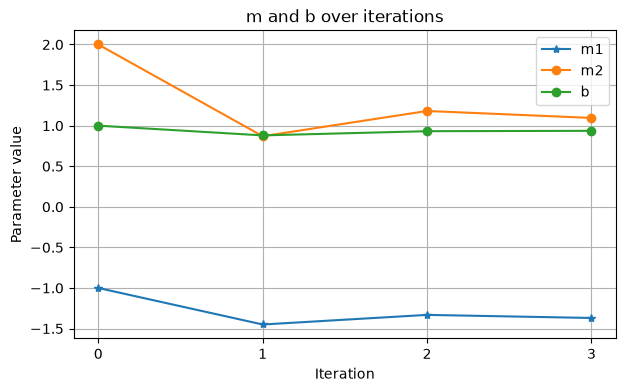

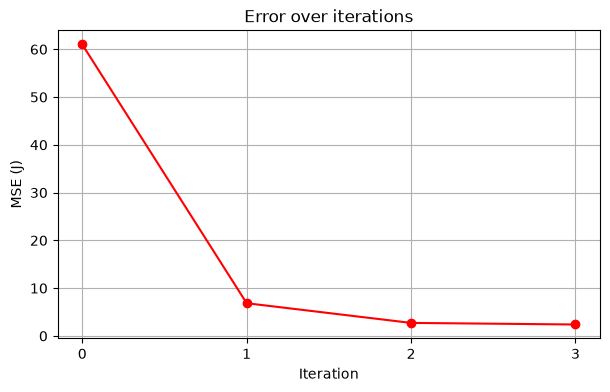

In [10]:
#the plots
iters = list(range(num_updates + 1))

plt.figure(figsize=(7, 4))
plt.plot(iters, history_m1, marker="*", label="m1")
plt.plot(iters, history_m2, marker="o", label="m2")
plt.plot(iters, history_b, marker="o", label="b")
plt.xlabel("Iteration")
plt.ylabel("Parameter value")
plt.title("m and b over iterations")
plt.xticks(iters)
plt.legend()
plt.grid(True)

plt.figure(figsize=(7, 4))
plt.plot(iters, history_J, marker="o", color="red")
plt.xlabel("Iteration")
plt.ylabel("MSE (J)")
plt.title("Error over iterations")
plt.xticks(iters)
plt.grid(True)

plt.show()